Connection established successfully!


C:\Users\DELL\AppData\Local\Temp\ipykernel_14968\55541403.py:23: UserWarning: pandas only supports SQLAlchemy connectable (engine/connection) or database string URI or sqlite3 DBAPI2 connection. Other DBAPI2 objects are not tested. Please consider using SQLAlchemy.
  df1 = pd.read_sql(query1, con)


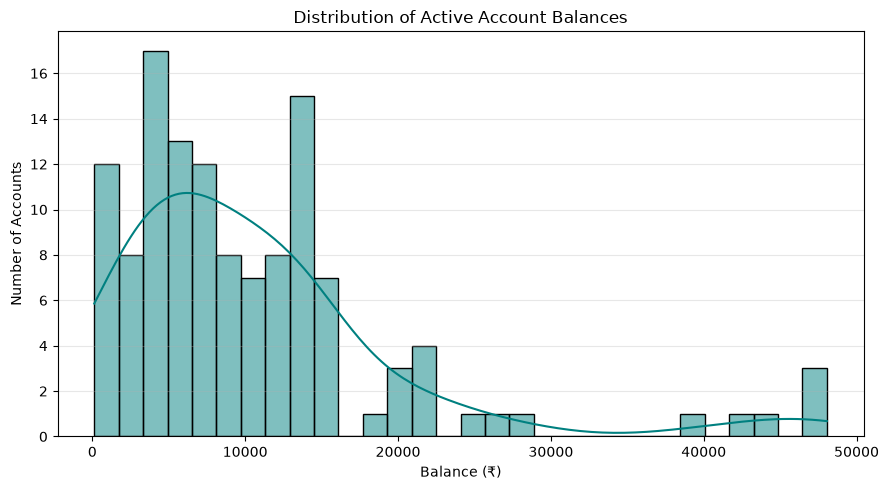

C:\Users\DELL\AppData\Local\Temp\ipykernel_14968\55541403.py:35: UserWarning: pandas only supports SQLAlchemy connectable (engine/connection) or database string URI or sqlite3 DBAPI2 connection. Other DBAPI2 objects are not tested. Please consider using SQLAlchemy.
  df2 = pd.read_sql(query2, con)


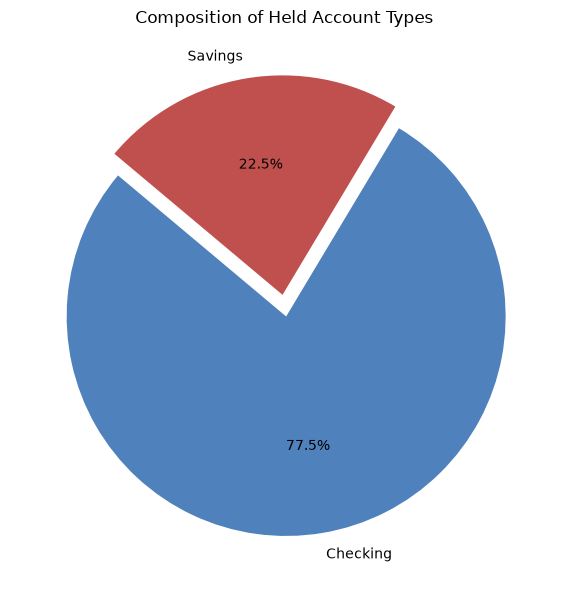

C:\Users\DELL\AppData\Local\Temp\ipykernel_14968\55541403.py:45: UserWarning: pandas only supports SQLAlchemy connectable (engine/connection) or database string URI or sqlite3 DBAPI2 connection. Other DBAPI2 objects are not tested. Please consider using SQLAlchemy.
  df3 = pd.read_sql(query3, con)


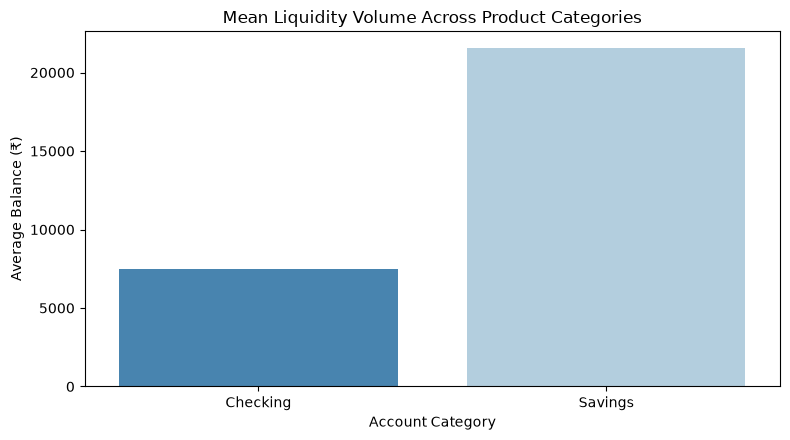

C:\Users\DELL\AppData\Local\Temp\ipykernel_14968\55541403.py:56: UserWarning: pandas only supports SQLAlchemy connectable (engine/connection) or database string URI or sqlite3 DBAPI2 connection. Other DBAPI2 objects are not tested. Please consider using SQLAlchemy.
  df4 = pd.read_sql(query4, con)


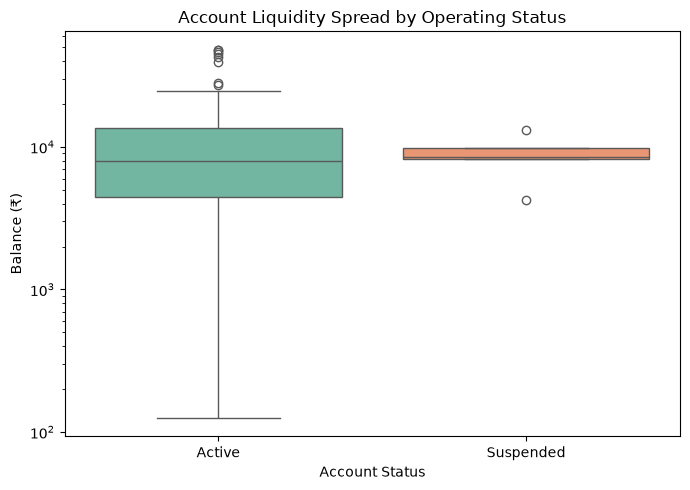

C:\Users\DELL\AppData\Local\Temp\ipykernel_14968\55541403.py:68: UserWarning: pandas only supports SQLAlchemy connectable (engine/connection) or database string URI or sqlite3 DBAPI2 connection. Other DBAPI2 objects are not tested. Please consider using SQLAlchemy.
  df5 = pd.read_sql(query5, con)


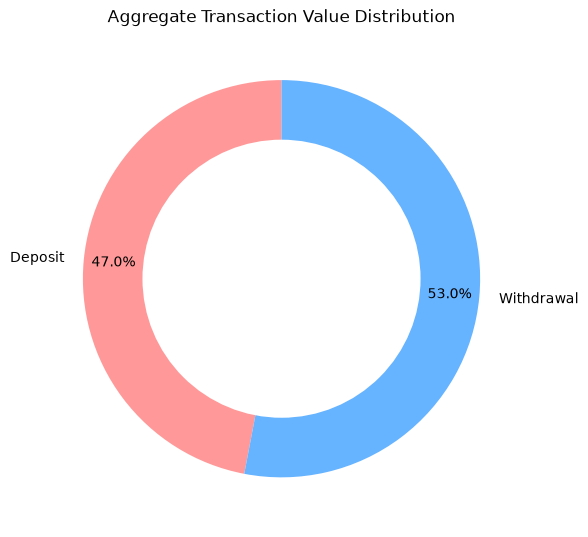

C:\Users\DELL\AppData\Local\Temp\ipykernel_14968\55541403.py:83: UserWarning: pandas only supports SQLAlchemy connectable (engine/connection) or database string URI or sqlite3 DBAPI2 connection. Other DBAPI2 objects are not tested. Please consider using SQLAlchemy.
  df6 = pd.read_sql(query6, con)


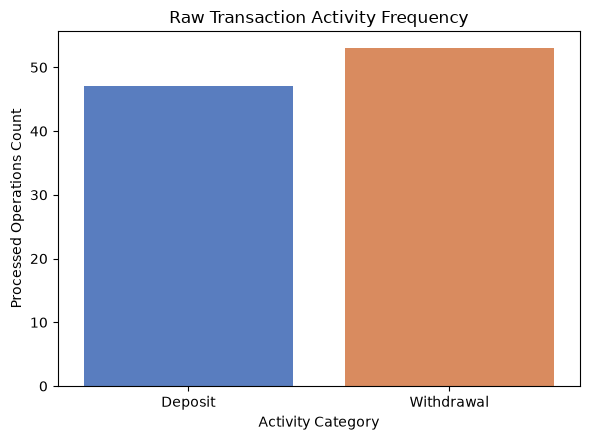

C:\Users\DELL\AppData\Local\Temp\ipykernel_14968\55541403.py:97: UserWarning: pandas only supports SQLAlchemy connectable (engine/connection) or database string URI or sqlite3 DBAPI2 connection. Other DBAPI2 objects are not tested. Please consider using SQLAlchemy.
  df7 = pd.read_sql(query7, con)


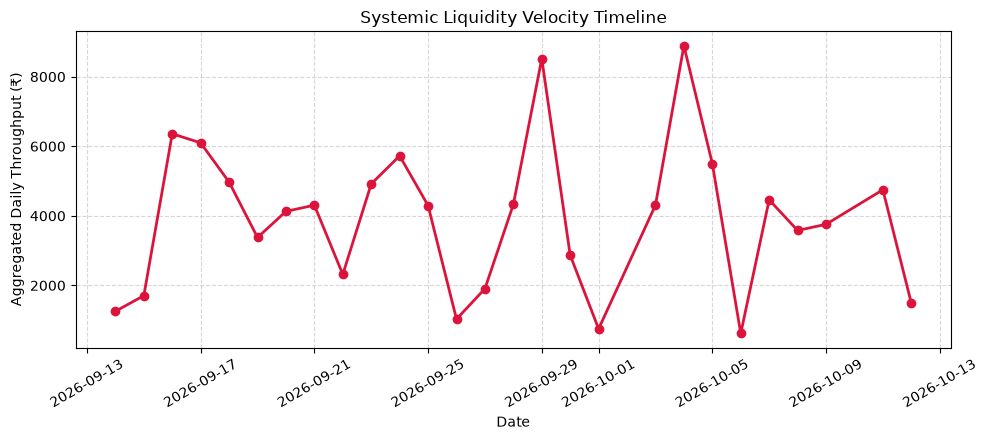

C:\Users\DELL\AppData\Local\Temp\ipykernel_14968\55541403.py:116: UserWarning: pandas only supports SQLAlchemy connectable (engine/connection) or database string URI or sqlite3 DBAPI2 connection. Other DBAPI2 objects are not tested. Please consider using SQLAlchemy.
  df8 = pd.read_sql(query8, con)


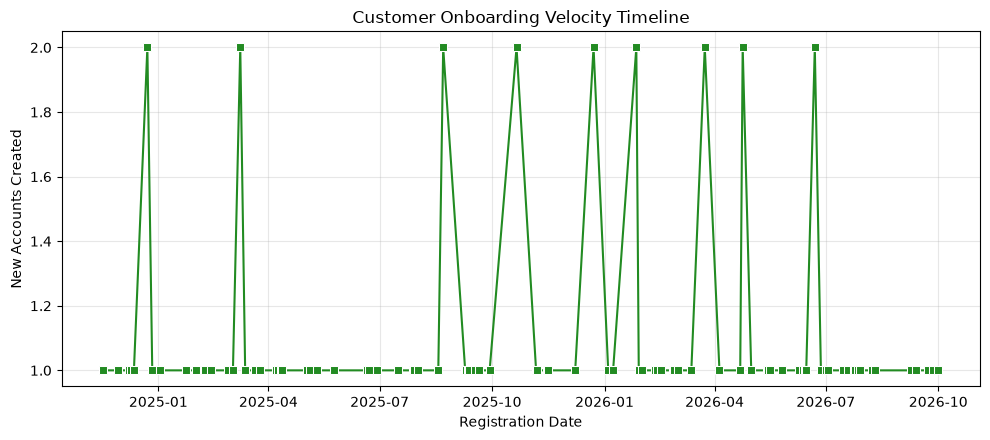

C:\Users\DELL\AppData\Local\Temp\ipykernel_14968\55541403.py:135: UserWarning: pandas only supports SQLAlchemy connectable (engine/connection) or database string URI or sqlite3 DBAPI2 connection. Other DBAPI2 objects are not tested. Please consider using SQLAlchemy.
  df9 = pd.read_sql(query9, con)


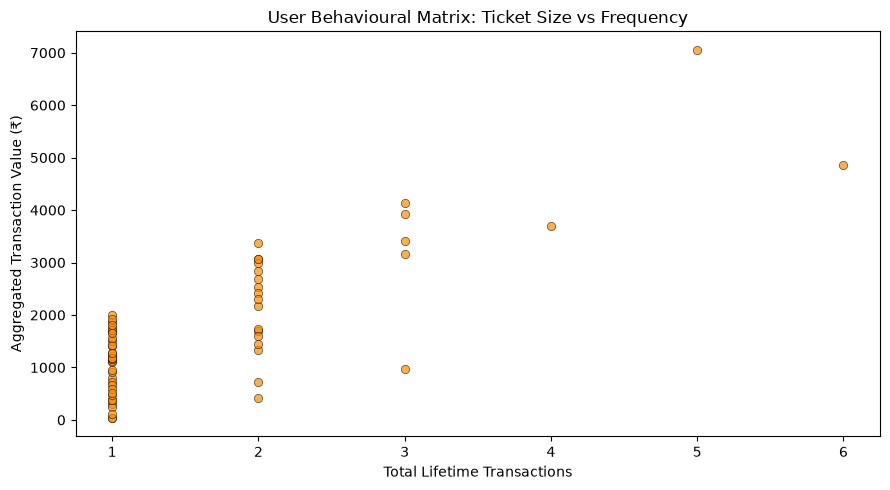

C:\Users\DELL\AppData\Local\Temp\ipykernel_14968\55541403.py:158: UserWarning: pandas only supports SQLAlchemy connectable (engine/connection) or database string URI or sqlite3 DBAPI2 connection. Other DBAPI2 objects are not tested. Please consider using SQLAlchemy.
  df10 = pd.read_sql(query10, con)


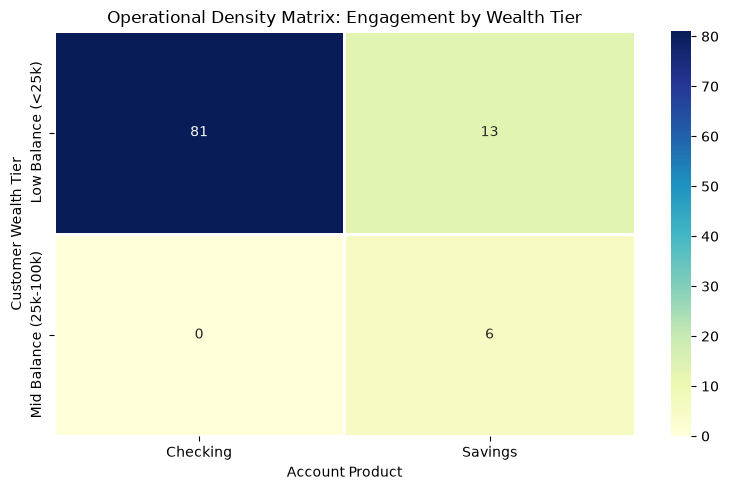

In [ ]:
import mysql.connector 

con= mysql.connector.connect(
        host="localhost",
        user="root",
        password="root",
        database="banking"
    )
print("Connection established successfully!")

cursor = con.cursor()
query = "SELECT * FROM customers"
cursor.execute(query)
results = cursor.fetchall()
# for row in results:
#     print(row)

import matplotlib.pyplot as plt
import seaborn as sns
import pandas as pd

#seaborn histplot

query1 = "SELECT Balance FROM Accounts WHERE Status = 'Active'"
df1 = pd.read_sql(query1, con)

plt.figure(figsize=(9, 5))
sns.histplot(df1['Balance'], kde=True, color='teal', bins=30)
plt.title('Distribution of Active Account Balances')
plt.xlabel('Balance (₹)')
plt.ylabel('Number of Accounts')
plt.grid(axis='y', alpha=0.3)
plt.tight_layout()
plt.show()

query2 = "SELECT AccountType, COUNT(*) as AccountCount FROM Accounts GROUP BY AccountType"
df2 = pd.read_sql(query2, con)

plt.figure(figsize=(6, 6))
plt.pie(df2['AccountCount'], labels=df2['AccountType'], autopct='%1.1f%%', 
        startangle=140, colors=['#4f81bd', '#c0504d', '#9bbb59'], explode=[0.05] * len(df2))
plt.title('Composition of Held Account Types')
plt.tight_layout()
plt.show()

query3 = "SELECT AccountType, AVG(Balance) as AvgBalance FROM Accounts GROUP BY AccountType"
df3 = pd.read_sql(query3, con)

plt.figure(figsize=(8, 4.5))
sns.barplot(x='AccountType', y='AvgBalance', data=df3, hue='AccountType', palette='Blues_r', legend=False)
plt.title('Mean Liquidity Volume Across Product Categories')
plt.xlabel('Account Category')
plt.ylabel('Average Balance (₹)')
plt.tight_layout()
plt.show()

query4 = "SELECT Status, Balance FROM Accounts"
df4 = pd.read_sql(query4, con)

plt.figure(figsize=(7, 5))
sns.boxplot(x='Status', y='Balance', data=df4, hue='Status', palette='Set2', legend=False)
plt.title('Account Liquidity Spread by Operating Status')
plt.xlabel('Account Status')
plt.ylabel('Balance (₹)')
plt.yscale('log')  
plt.tight_layout()
plt.show()

query5 = "SELECT TransactionType, SUM(Amount) as TotalVolume FROM Transactions GROUP BY TransactionType"
df5 = pd.read_sql(query5, con)

plt.figure(figsize=(6, 6))
plt.pie(df5['TotalVolume'], labels=df5['TransactionType'], autopct='%1.1f%%', 
        startangle=90, pctdistance=0.85, colors=['#ff9999','#66b3ff'])
# Create center circle to turn it into a donut chart
centre_circle = plt.Circle((0,0),0.70,fc='white')
fig = plt.gcf()
fig.gca().add_artist(centre_circle)

plt.title('Aggregate Transaction Value Distribution')
plt.tight_layout()
plt.show()

query6 = "SELECT TransactionType FROM Transactions"
df6 = pd.read_sql(query6, con)

plt.figure(figsize=(6, 4.5))
sns.countplot(x='TransactionType', data=df6, hue='TransactionType', palette='muted', legend=False)
plt.title('Raw Transaction Activity Frequency')
plt.xlabel('Activity Category')
plt.ylabel('Processed Operations Count')
plt.tight_layout()
plt.show()

query7 = """SELECT DATE(TransactionDate) as TxDate, SUM(Amount) as DailyVolume 
    FROM Transactions 
    GROUP BY DATE(TransactionDate) 
    ORDER BY TxDate"""
df7 = pd.read_sql(query7, con)
df7['TxDate'] = pd.to_datetime(df7['TxDate'])

plt.figure(figsize=(10, 4.5))
plt.plot(df7['TxDate'], df7['DailyVolume'], color='crimson', marker='o', linewidth=2)
plt.title('Systemic Liquidity Velocity Timeline')
plt.xlabel('Date')
plt.ylabel('Aggregated Daily Throughput (₹)')
plt.xticks(rotation=30)
plt.grid(True, linestyle='--', alpha=0.5)
plt.tight_layout()
plt.show()

query8 = """
    SELECT DATE(CreatedAt) as RegDate, COUNT(CustomerID) as NewUsers 
    FROM Customers 
    GROUP BY DATE(CreatedAt) 
    ORDER BY RegDate
"""
df8 = pd.read_sql(query8, con)
df8['RegDate'] = pd.to_datetime(df8['RegDate'])

plt.figure(figsize=(10, 4.5))
sns.lineplot(x='RegDate', y='NewUsers', data=df8, color='forestgreen', marker='s')
plt.title('Customer Onboarding Velocity Timeline')
plt.xlabel('Registration Date')
plt.ylabel('New Accounts Created')
plt.grid(True, alpha=0.3)
plt.tight_layout()
plt.show()


query9 = """
    SELECT a.CustomerID, COUNT(t.TransactionID) as TxCount, SUM(t.Amount) as TotalSpent
    FROM Accounts a
    JOIN Transactions t ON a.AccountID = t.AccountID
    GROUP BY a.CustomerID
"""
df9 = pd.read_sql(query9, con)

plt.figure(figsize=(9, 5))
sns.scatterplot(x='TxCount', y='TotalSpent', data=df9, alpha=0.7, color='darkorange', edgecolor='black')
plt.title('User Behavioural Matrix: Ticket Size vs Frequency')
plt.xlabel('Total Lifetime Transactions')
plt.ylabel('Aggregated Transaction Value (₹)')
plt.tight_layout()
plt.show()

query10 = """
    SELECT 
        CASE 
            WHEN Balance < 25000 THEN 'Low Balance (<25k)'
            WHEN Balance BETWEEN 25000 AND 100000 THEN 'Mid Balance (25k-100k)'
            ELSE 'High Net Worth (>100k)'
        END as BalanceTier,
        AccountType,
        COUNT(t.TransactionID) as TotalTxCount
    FROM Accounts a
    LEFT JOIN Transactions t ON a.AccountID = t.AccountID
    GROUP BY BalanceTier, AccountType
"""
df10 = pd.read_sql(query10, con)

# Reshape into cross-tabulated structure for the heatmap matrix
pivot_df = df10.pivot(index='BalanceTier', columns='AccountType', values='TotalTxCount').fillna(0)

plt.figure(figsize=(8, 5))
sns.heatmap(pivot_df, annot=True, fmt=".0f", cmap='YlGnBu', linewidths=1)
plt.title('Operational Density Matrix: Engagement by Wealth Tier')
plt.xlabel('Account Product')
plt.ylabel('Customer Wealth Tier')
plt.tight_layout()
plt.show()



C:\Users\DELL\AppData\Local\Temp\ipykernel_14968\3339552113.py:7: UserWarning: pandas only supports SQLAlchemy connectable (engine/connection) or database string URI or sqlite3 DBAPI2 connection. Other DBAPI2 objects are not tested. Please consider using SQLAlchemy.
  df1 = pd.read_sql(query1, con)
C:\Users\DELL\AppData\Local\Temp\ipykernel_14968\3339552113.py:10: UserWarning: pandas only supports SQLAlchemy connectable (engine/connection) or database string URI or sqlite3 DBAPI2 connection. Other DBAPI2 objects are not tested. Please consider using SQLAlchemy.
  df2 = pd.read_sql(query2, con)
C:\Users\DELL\AppData\Local\Temp\ipykernel_14968\3339552113.py:13: UserWarning: pandas only supports SQLAlchemy connectable (engine/connection) or database string URI or sqlite3 DBAPI2 connection. Other DBAPI2 objects are not tested. Please consider using SQLAlchemy.
  df3 = pd.read_sql(query3, con)
C:\Users\DELL\AppData\Local\Temp\ipykernel_14968\3339552113.py:22: UserWarning: pandas only suppor

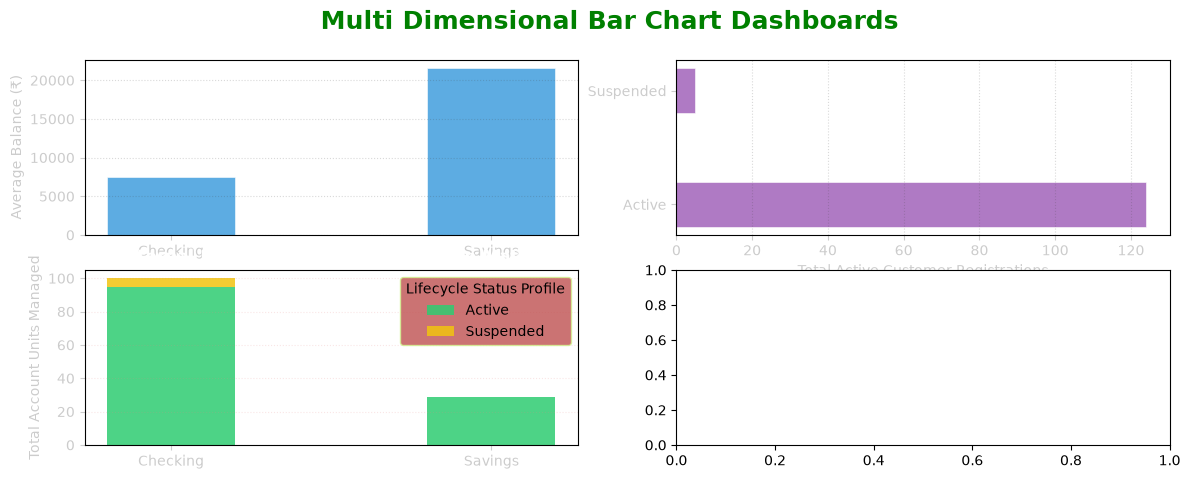

In [ ]:
#Dashboard 1 - 4 charts
import matplotlib.pyplot as plt
import seaborn as sns
import pandas as pd

query1 = "SELECT AccountType, AVG(Balance) as AvgBalance FROM Accounts GROUP BY AccountType"
df1 = pd.read_sql(query1, con)
    
query2 = "SELECT Status, COUNT(*) as AccountCount FROM Accounts GROUP BY Status"
df2 = pd.read_sql(query2, con)
    
query3 = "SELECT AccountType, Status, COUNT(*) as Count FROM Accounts GROUP BY AccountType, Status"
df3 = pd.read_sql(query3, con)
pivot_df3 = df3.pivot(index='AccountType', columns='Status', values='Count').fillna(0)

query4 = """
        SELECT a.AccountType, t.TransactionType, SUM(t.Amount) as TotalVolume
        FROM Accounts a
        JOIN Transactions t ON a.AccountID = t.AccountID
        GROUP BY a.AccountType, t.TransactionType
    """
df4 = pd.read_sql(query4, con)
pivot_df4 = df4.pivot(index='AccountType', columns='TransactionType', values='TotalVolume').fillna(0)


fig, axs = plt.subplots(2, 2, figsize=(14, 5))
fig.suptitle('Multi Dimensional Bar Chart Dashboards',fontsize=18,fontweight='bold',color='Green')
#char1 - Standard Bar Chart
axs[0, 0].bar(df1['AccountType'], df1['AvgBalance'], color='#3498db', alpha=0.8, width=0.4, edgecolor='#ffffff', linewidth=0.5)
axs[0, 0].set_title('Mean Liquidity Benchmarks Across Account Tiers', fontsize=12, fontweight='bold', color='#ffffff')
axs[0, 0].set_ylabel('Average Balance (₹)', color='#cccccc')
axs[0, 0].grid(axis='y', linestyle=':', alpha=0.2, color='#444444')
axs[0, 0].tick_params(colors='#cccccc')

#Horizontal Bar Chart
axs[0, 1].barh(df2['Status'], df2['AccountCount'], color='#9b59b6', alpha=0.8, height=0.4, edgecolor='#ffffff', linewidth=0.5)
axs[0, 1].set_title('Structural Account Base Distributed by Operating Status', fontsize=12, fontweight='bold', color='#ffffff')
axs[0, 1].set_xlabel('Total Active Customer Registrations', color='#cccccc')
axs[0, 1].grid(axis='x', linestyle=':', alpha=0.2, color='#444444')
axs[0, 1].tick_params(colors='#cccccc')

#stacked Bar Chart
import numpy as np
bottom_track = np.zeros(len(pivot_df3))
colors_stacked = ['#2ecc71', '#f1c40f', '#e74c3c'] # Active, Dormant, Suspended hex mapping

for i, col_name in enumerate(pivot_df3.columns):
    axs[1, 0].bar(pivot_df3.index, pivot_df3[col_name], bottom=bottom_track, 
                  label=col_name, color=colors_stacked[i % len(colors_stacked)], alpha=0.85, width=0.4)
    bottom_track += pivot_df3[col_name].values


axs[1, 0].set_title('Internal Portfolio Lifecycle Allocation Matrix', fontsize=12, fontweight='bold', color='#ffffff')
axs[1, 0].set_ylabel('Total Account Units Managed', color='#cccccc')
axs[1, 0].legend(title="Lifecycle Status Profile", facecolor="#bf5050", edgecolor="#D2F58E")
axs[1, 0].grid(axis='y', linestyle=':', alpha=0.2, color="#E58484")
axs[1, 0].tick_params(colors='#cccccc')

x_indexes = np.arange(len(pivot_df4.index))
bar_width = 0.25

# Generate side-by-side shifts by adjusting base x coordinates manually
if 'Deposit' in pivot_df4.columns:
    axs[1, 1].bar(x_indexes - bar_width/2, pivot_df4['Deposit'], 
                  width=bar_width, label='Deposits (Inflow)', color='#2ecc71', alpha=0.8)
if 'Withdrawal' in pivot_df4.columns:
    axs[1, 1].bar(x_indexes + bar_width/2, pivot_df4['Withdrawal'], 
                  width=bar_width, label='Withdrawals (Outflow)', color='#e74c3c', alpha=0.8)

axs[1, 1].set_title('Volumetric Cash Operations Flow Matrix', fontsize=12, fontweight='bold', color='#ffffff')
axs[1, 1].set_xticks(x_indexes)
axs[1, 1].set_xticklabels(pivot_df4.index)
axs[1, 1].set_ylabel('Total Processing Throughput Volume (₹)', color='#cccccc')
axs[1, 1].legend(title="Transaction Mode", facecolor='#1e1e1e', edgecolor='#444444')
axs[1, 1].grid(axis='y', linestyle=':', alpha=0.2, color='#444444')
axs[1, 1].tick_params(colors='#cccccc')

plt.show()

In [ ]:
Dashboard2 - 4 Charts
